# Text-only analysis: text preparation, text features and text-only classifiers

This notebook covers only the **text side** of the project: no co-purchase graph is used by any model here. Its sections follow the report's *Text and Feature Preparation* section and the LLM paragraph of the literature review.

| Section | What it shows | Report |
|---|---|---|
| 1 | File fingerprints and text-to-node alignment | "checked against recorded file fingerprints… each text row is verified" |
| 2 | Format-only cleaning of product text and GPT explanations | cleaning paragraph |
| 3 | Text features: frozen MiniLM, GPT's ranked answers, fine-tuned DeBERTa, OGB features | feature paragraph |
| 4 | Token limits and truncation (MiniLM 256, DeBERTa 512) | truncation paragraph |
| 5 | Text-only classifiers, all fully trained | results |
| 6 | Comparison table, and the three LLM questions | results; LLM paragraph |
| 7 | Does truncation hurt accuracy? | Appendix A |

**How TAPE's GPT-3.5 responses are tested (three ways), plus a reference:**
- as text encoded by frozen MiniLM: arm **G** (product text + explanation), against its capacity control **K**
- as one-hot features from GPT's ranked answers: arm **P_MLP**
- through the reproduction of TAPE's fine-tuning stage: **DeBERTa-expl** vs **DeBERTa-orig**
- reference: **GPT's first answer on its own**, with no training

The notebook finds the repository root itself, so it runs from `notebooks/2_text_only/`. Steps whose outputs already exist in `results/2_text_only/` are skipped unless `FORCE = True`.

**About the saved outputs.** The tables below come from the run recorded in this notebook. Three of its result files (`text_only_runs.csv`, `ogb_mlp_runs.csv`, `truncation_*.csv`) and `scripts/run_ogb_mlp.py` are not in the repository, so a rerun trains those arms again; on another machine `scripts/run_text_only.py` gives numbers within 0.1–0.3 points of the saved ones. The Text Transformer row (test 0.637) is from this notebook's run; `results/2_text_only/text_transformer_runs.csv` holds an earlier run of the same script (test 0.645).

## 0. Setup

In [1]:
import json, hashlib, os, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch

REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "requirements.txt").is_file() and (p / "src").is_dir())  # works from anywhere in the repo
os.chdir(REPO)
sys.path.insert(0, str(REPO))
assert (REPO / "scripts").is_dir() and (REPO / "src").is_dir(), f"{REPO} does not look like the repo root"

SMOKE = False   # True: train for 5 epochs only, to check the pipeline; smoke results are left out of the tables
FORCE = False   # True: redo steps whose outputs already exist
EPOCHS = 5 if SMOKE else None
SMOKE_EPOCHS = 5


def run(script, *args, python=None):
    """Run scripts/<script>.py in a fresh process and stream its output. Interrupt (stop button) ends it."""
    cmd = [python or sys.executable, f"scripts/{script}.py", *map(str, args)]
    print("$", " ".join(cmd), flush=True)
    env = {**os.environ, "PYTHONIOENCODING": "utf-8", "PYTHONUTF8": "1"}
    proc = subprocess.Popen(cmd, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace", env=env)
    try:
        for line in proc.stdout:
            print(line, end="")
    except KeyboardInterrupt:
        proc.kill()
        proc.wait()
        print(f"\n{script} stopped by user")
        return
    if proc.wait() != 0:
        raise RuntimeError(f"{script} failed with exit code {proc.returncode}")


def epochs_pos():
    return [] if EPOCHS is None else [EPOCHS]


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def fully_trained(runs_csv):
    """True if a results file exists and its runs went past the smoke-test cap."""
    path = REPO / "results" / "2_text_only" / runs_csv
    if not path.exists():
        return False
    runs = pd.read_csv(path)
    return "epochs_run" not in runs or runs.epochs_run.max() > SMOKE_EPOCHS

## 1. Data integrity

`load_products()` loads the graph file only after its SHA-256 fingerprint matches `data/TAPE/download_manifest.json`, and asserts that CSV row *i* is graph node *i* (`uid == n_asin`, `nid == n_id`). `load_tape_explanations()` reads TAPE's GPT-3.5 responses only after the archive matches `results/shared/tape_gpt_responses_manifest.json`. Only node labels and split masks are used from the graph here.

In [2]:
from src.data import load_products, load_tape_explanations

graph, text = load_products()                     # fingerprint check + row-to-node alignment asserts
N = graph.num_nodes
expl = load_tape_explanations(N)                  # fingerprint check of TAPE's GPT-response archive
assert len(text) == len(expl) == N

masks = {s: graph[f"{s}_mask"] for s in ["train", "val", "test"]}
assert int(sum(m.long() for m in masks.values()).max()) == 1, "splits overlap"
y = graph.y
assert int(y.min()) >= 0 and int(y.max()) < 47, "label outside 0..46"
print(f"{N} products; text rows aligned with graph nodes; {len(expl)} GPT responses")
print({s: int(m.sum()) for s, m in masks.items()})
print("categories present:", {s: int(y[m].unique().numel()) for s, m in masks.items()})

<home>\miniconda3\envs\cs5284\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


54025 products; text rows aligned with graph nodes; 54025 GPT responses
{'train': 14708, 'val': 1572, 'test': 37745}
categories present: {'train': 33, 'val': 26, 'test': 40}


## 2. Text cleaning (format only)

`src/text_clean.py` changes markup and whitespace only. Missing values become empty strings; HTML entities are decoded (repeatedly, as some are encoded several times); hidden script, style and Office blocks, leftover CSS and genuine HTML tags are removed; whitespace is collapsed. Product wording, including marketing language, is kept. The same `clean_text` is applied to GPT explanations. Product text is then formatted as `Product: {title}; Description: {content}`.

This cleaned text feeds MiniLM and the text Transformer. The DeBERTa reproduction instead uses TAPE's uncleaned format (Section 3.3).

In [3]:
from src.text_clean import build_original_text, clean_text

missing_title, missing_desc = text.title.isna(), text.content.isna()
print(f"missing title: {missing_title.sum()} ({missing_title.mean():.1%}); "
      f"missing description: {missing_desc.sum()} ({missing_desc.mean():.1%}); "
      f"both: {(missing_title & missing_desc).sum()}")

markup = text.content.fillna("").str.contains(r"<[a-zA-Z/!]|&[a-zA-Z#0-9]+;", regex=True)
print(f"descriptions containing markup or HTML entities: {markup.sum()} ({markup.mean():.1%})")
changed = sum(build_original_text(t, c) != f"Product: {t}; Description: {c}"
              for t, c in zip(text.title.fillna(""), text.content.fillna("")))
print(f"product texts changed by cleaning: {changed} ({changed / N:.1%})\n")

for i in np.flatnonzero(markup.values)[:3]:
    print("RAW    :", repr(str(text.content[i])[:250]))
    print("CLEANED:", repr(clean_text(text.content[i])[:250]), "\n")

i = int(np.flatnonzero(missing_title.values)[0])
print("missing title ->", repr(build_original_text(text.title[i], text.content[i])[:120]))
print("GPT explanation, cleaned ->", repr(clean_text(expl[0])[:200]))

missing title: 4903 (9.1%); missing description: 3846 (7.1%); both: 579
descriptions containing markup or HTML entities: 9444 (17.5%)
product texts changed by cleaning: 14177 (26.2%)

RAW    : 'Absolute premium, this advanced eye serum delivers a concentrated dose of powerful thermo-water minerals with organic, restorative natural flora for an immediate replenishing effect. This superior, fast-acting serum was designed specifically for the '
CLEANED: 'Absolute premium, this advanced eye serum delivers a concentrated dose of powerful thermo-water minerals with organic, restorative natural flora for an immediate replenishing effect. This superior, fast-acting serum was designed specifically for the ' 

RAW    : '"The authors apply years of experience in both the clinic and classroom to address a broad clinical audience. The book is geared toward residents, fellows, and junior faculty, although students could make use of it early in their evidence-based medic'
CLEANED: '"The authors apply

## 3. Text features

### 3.1 Frozen MiniLM embeddings (product text and GPT explanation)

`all-MiniLM-L6-v2`, pinned to one revision, encodes each cleaned text into a 384-dimensional vector with its lower-cased vocabulary and a 256-token limit. Each embedding file gets a manifest with encoder, revision, shape, data type and SHA-256 fingerprint. Skipped if the file already matches its manifest.

In [4]:
for script, name in [("encode_original", "original__all-MiniLM-L6-v2"), ("encode_tape", "tape__all-MiniLM-L6-v2")]:
    npy = REPO / "outputs" / "embeddings" / f"{name}.npy"
    manifest = REPO / "results" / "shared" / "embeddings" / f"{name}.json"
    up_to_date = npy.exists() and manifest.exists() and sha256(npy) == json.loads(manifest.read_text())["sha256"]
    if up_to_date and not FORCE:
        print(f"{name}: matches its manifest, skipped")
    else:
        run(script)

original__all-MiniLM-L6-v2: matches its manifest, skipped
tape__all-MiniLM-L6-v2: matches its manifest, skipped


In [5]:
# Every embedding manifest in results/shared/embeddings/ (MiniLM, and DeBERTa once its outputs are in place)
rows = []
for manifest in sorted((REPO / "results" / "shared" / "embeddings").glob("*.json")):
    m = json.loads(manifest.read_text())
    candidates = [REPO / "outputs" / "embeddings" / m.get("file", ""), REPO / "outputs" / "tape_lm" / m.get("file", "")]
    found = next((p for p in candidates if p.is_file()), None)
    rows.append({"manifest": manifest.name, "text variant": m.get("text_variant", m.get("text", "")),
                 "encoder": m.get("encoder", m.get("model", "")), "revision": str(m.get("encoder_revision", ""))[:10],
                 "shape": m.get("shape", ""), "dtype": m.get("dtype", ""),
                 "file matches fingerprint": None if found is None else sha256(found) == m.get("sha256")})
pd.DataFrame(rows)

,manifest,text variant,encoder,revision,shape,dtype,file matches fingerprint
0,original__all-MiniLM-L6-v2.json,original,sentence-transformers/all-MiniLM-L6-v2,1110a243fd,"[54025, 384]",float32,True
1,tape__all-MiniLM-L6-v2.json,tape_explanation,sentence-transformers/all-MiniLM-L6-v2,1110a243fd,"[54025, 384]",float32,True
2,tape_lm_expl_deberta-base_seed0.json,tape_explanation,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
3,tape_lm_expl_deberta-base_seed1.json,tape_explanation,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
4,tape_lm_expl_deberta-base_seed2.json,tape_explanation,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
5,tape_lm_orig_deberta-base_seed0.json,original,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
6,tape_lm_orig_deberta-base_seed0_ex-testlike.json,original,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
7,tape_lm_orig_deberta-base_seed1.json,original,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None
8,tape_lm_orig_deberta-base_seed2.json,original,"microsoft/deberta-base, fine-tuned on the trai...",not pinned,"[54025, 768]",float16,None


### 3.2 GPT's ranked category answers

TAPE's prompt lists every category name, and GPT-3.5 answers with the most likely ones. `src/gpt_parse.py` takes category names in order of first appearance (longest name wins at the same position). The first three answers become a 3 × 47 one-hot block (arm P_MLP); a missing answer is all zeros, and for GPT on its own it counts as wrong.

In [6]:
from src.gpt_parse import category_patterns, ranked_categories

patterns = category_patterns()
rank = torch.tensor([ranked_categories(t, patterns, 3) for t in expl])
answers = (rank >= 0).sum(1)
print("products by number of parsed GPT answers (0-3):", answers.bincount(minlength=4).tolist())
print("no answer at all:", {s: f"{float((rank[m, 0] < 0).float().mean()):.1%}" for s, m in masks.items()})

products by number of parsed GPT answers (0-3): [1132, 506, 483, 51904]
no answer at all: {'train': '3.0%', 'val': '2.3%', 'test': '1.8%'}


### 3.3 Fine-tuned DeBERTa (TAPE's language-model stage)

`microsoft/deberta-base` is fine-tuned in `notebooks/2_text_only/tape_lm_colab.ipynb` on TAPE's **uncleaned** input format: `Product:{title}; Description: {content}\n` with missing values as "nan", and separately on the raw GPT explanation. Its case-sensitive tokeniser cuts at 512 tokens. Each product is represented by the 768-dimensional summary vector at the [CLS] position, on which the category classifier is trained. TAPE's settings (4 epochs, learning rate 2×10⁻⁵, label smoothing 0.3, half precision) are kept except the batch size, 9 on one GPU instead of TAPE's effective 36.

1. Export the inputs (seconds).
2. **Manual step:** run `notebooks/2_text_only/tape_lm_colab.ipynb` on a Colab T4 (about 2 hours per seed), then download the outputs and `manifest.json` from `My Drive/cs5284/tape_lm/out/` into `outputs/tape_lm/`.
3. Verify the downloads.

In [7]:
parts = sorted((REPO / "outputs" / "tape_lm").glob("tape_lm_input_part*.jsonl.gz"))
if len(parts) == 4 and not FORCE:
    print("DeBERTa input files present, skipped:", [p.name for p in parts])
else:
    run("export_tape_lm_input")

DeBERTa input files present, skipped: ['tape_lm_input_part0.jsonl.gz', 'tape_lm_input_part1.jsonl.gz', 'tape_lm_input_part2.jsonl.gz', 'tape_lm_input_part3.jsonl.gz']


In [8]:
if (REPO / "outputs" / "tape_lm" / "manifest.json").exists():
    run("verify_manifest", "outputs/tape_lm")
else:
    print("No outputs/tape_lm/manifest.json yet: download the Colab outputs first.")

# DeBERTa's own validation accuracy, as recorded by the Colab notebook
meta_rows = []
for p in sorted((REPO / "outputs" / "tape_lm").glob("tape_lm_*_deberta-base_seed*.json")):
    m = json.loads(p.read_text())
    meta_rows.append({"run": p.stem, "text": m.get("text"), "seed": m.get("seed"), "plan": m.get("plan"),
                      "val_acc (DeBERTa alone)": m.get("val_acc_fp16_inference"), "best_step": m.get("best_step"),
                      "train_minutes": round(m.get("train_minutes", float("nan")), 1)})
pd.DataFrame(meta_rows) if meta_rows else print("No DeBERTa run metadata in outputs/tape_lm/ yet.")

No outputs/tape_lm/manifest.json yet: download the Colab outputs first.
No DeBERTa run metadata in outputs/tape_lm/ yet.


### 3.4 Released OGB features and word-importance vectors

The **OGB features** (100 dimensions, bag of words compressed with PCA) come with the dataset; `scripts/run_ogb_mlp.py` reads them from the fingerprint-checked graph file and standardises them with training-node statistics only. The **word-importance vectors compressed to a fixed length** (TF-IDF with truncated SVD) belong to another pipeline (R5) and are not run in this notebook.

## 4. Token limits and truncation

MiniLM reads at most 256 tokens of the cleaned text; DeBERTa reads at most 512 tokens of TAPE's uncleaned text. Lengths are counted without truncation, special tokens included, so "truncated" means longer than the limit. DeBERTa's lengths use the exact texts exported for Colab.

In [9]:
import glob, gzip
from transformers import AutoTokenizer
from src.encode import load_encoder

def token_lengths(tok, texts):
    return np.array([len(ids) for ids in tok(list(texts), add_special_tokens=True, verbose=False)["input_ids"]])

minilm_tok = load_encoder().tokenizer
deberta_tok = AutoTokenizer.from_pretrained("microsoft/deberta-base")

recs = []
for path in sorted(glob.glob(str(REPO / "outputs" / "tape_lm" / "tape_lm_input_part*.jsonl.gz"))):
    with gzip.open(path, "rt", encoding="utf-8") as f:
        recs += [json.loads(line) for line in f]
assert [r["i"] for r in recs] == list(range(N)), "run Section 3.3 first: DeBERTa input files missing or incomplete"

inputs = {
    ("MiniLM", "product text"): (minilm_tok, [build_original_text(t, c) for t, c in zip(text.title, text.content)], 256),
    ("MiniLM", "GPT explanation"): (minilm_tok, [clean_text(e) for e in expl], 256),
    ("DeBERTa", "product text"): (deberta_tok, [r["orig"] for r in recs], 512),
    ("DeBERTa", "GPT explanation"): (deberta_tok, [r["expl"] for r in recs], 512),
}
split_name = np.where(masks["train"].numpy(), "train", np.where(masks["val"].numpy(), "val", "test"))
lengths, rows = {}, []
for (encoder, variant), (tok, texts, limit) in inputs.items():
    L = lengths[(encoder, variant)] = token_lengths(tok, texts)
    rows.append({"encoder": encoder, "text": variant, "limit": limit,
                 "truncated": f"{(L > limit).mean():.1%}", "median": int(np.median(L)),
                 "95th pct": int(np.percentile(L, 95)),
                 **{f"{s} truncated": f"{(L[split_name == s] > limit).mean():.1%}" for s in ["train", "val", "test"]}})
pd.DataFrame(rows)

<home>\miniconda3\envs\cs5284\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


,encoder,text,limit,truncated,median,95th pct,train truncated,val truncated,test truncated
0,MiniLM,product text,256,16.3%,106,417,19.5%,18.7%,14.9%
1,MiniLM,GPT explanation,256,4.8%,173,255,4.4%,5.5%,4.9%
2,DeBERTa,product text,512,2.9%,110,427,4.0%,3.6%,2.5%
3,DeBERTa,GPT explanation,512,0.0%,184,269,0.0%,0.0%,0.0%


## 5. Text-only classifiers

Every trained classifier below sees only per-product features, never the co-purchase graph. The MLPs share one head (2 layers, hidden 256, dropout 0.5, weight decay 5×10⁻⁴, early stopping on validation accuracy with patience 50, seeds 0–2, 4 CPU threads), so differences between them come from the features.

### 5.1 GPT-3.5's first answer, no training (reference)

In [10]:
from src.train import masked_metrics

gpt_rows = [{"eval": s, **masked_metrics(y, rank[:, 0], m)} for s, m in masks.items() if s != "train"]
pd.DataFrame(gpt_rows).round(4)

,eval,acc,macro_f1
0,val,0.7831,0.5409
1,test,0.7235,0.3811


### 5.2 MLP on the released OGB features

In [11]:
if fully_trained("ogb_mlp_runs.csv") and not FORCE and not SMOKE:
    print("results/2_text_only/ogb_mlp_runs.csv is a full run, skipped")
elif not (REPO / "scripts" / "run_ogb_mlp.py").exists():
    print("scripts/run_ogb_mlp.py is not in the repository; the OGB-feature MLP numbers are in this notebook's saved outputs")
else:
    run("run_ogb_mlp", *epochs_pos())

results/ogb_mlp_runs.csv is a full run, skipped


### 5.3 MLPs on frozen MiniLM features: A, K, G, P_MLP
`scripts/run_text_only.py`: product text (A); product text plus random dimensions (K, the capacity control for G); product text plus GPT explanation (G); product text plus GPT's ranked answers (P_MLP).

In [12]:
if fully_trained("text_only_runs.csv") and not FORCE and not SMOKE:
    print("results/2_text_only/text_only_runs.csv is a full run, skipped")
else:
    run("run_text_only", *epochs_pos())

results/text_only_runs.csv is a full run, skipped


### 5.4 Text Transformer trained from scratch (T)
Reuses MiniLM's vocabulary but none of its weights; a small grid on seed 0, then three seeds. It is skipped if results exist. Its run is not shortened by `SMOKE`.

In [13]:
if fully_trained("text_transformer_runs.csv") and not FORCE:
    print("results/2_text_only/text_transformer_runs.csv exists, skipped")
else:
    run("run_text_transformer")

results/text_transformer_runs.csv exists, skipped


### 5.5 Fine-tuned DeBERTa: with an MLP on its summary vectors, and on its own
- **+ MLP:** `scripts/run_tape_repro.py --config ours` trains the same MLP head on the 768-dimensional vectors (3 DeBERTa seeds × 3 MLP seeds). That script also trains graph models, so this notebook only reads its MLP rows. To regenerate: `run("run_tape_repro", "--config", "ours", "--lm-seed", s)` for s = 0, 1, 2.
- **Alone:** DeBERTa's own classifier, read from `outputs/tape_lm/tape_lm_{orig,expl}_deberta-base_seed*.pred.npy`.

In [14]:
files = sorted((REPO / "results" / "3_gnn_text").glob("tape_repro_ours_lm*_runs.csv"))
print("DeBERTa + MLP results:", [f.name for f in files] or "none yet")

DeBERTa + MLP results: ['tape_repro_ours_lm0_runs.csv', 'tape_repro_ours_lm1_runs.csv', 'tape_repro_ours_lm2_runs.csv']


## 6. Comparison of text-only classifiers (validation)

Validation products are best-sellers, like training; the long-tail test set is evaluated once at the end. Rows from smoke-test runs are left out and listed. `GPT-derived` marks rows that use TAPE's GPT-3.5 responses.

In [18]:
R = REPO / "results" / "2_text_only"

def read(name):
    path = R / name
    return pd.read_csv(path) if path.exists() else None

def build_table(split="val", extra_slices=()):
    """Text-only comparison on one split ('val' or 'test'), mean ± std over seeds.
    extra_slices: further evaluation slices to add as macro-F1 columns, e.g. ('test_seen', 'test_dedup')."""
    out, skipped, missing = [], [], []

    def add(label, df, features, model, gpt):
        if df is None or not len(df):
            return
        v = df[df["eval"] == split]
        if not len(v):
            missing.append(label)            # e.g. DeBERTa + MLP: its runs never evaluate test
            return
        if "epochs_run" in v and v.epochs_run.notna().any() and v.epochs_run.max() <= SMOKE_EPOCHS:
            skipped.append(label)
            return
        row = {"model": label, "features": features, "classifier": model, "GPT-derived": gpt,
               f"{split}_acc": v.acc.mean(), "acc_std": v.acc.std(),
               f"{split}_macro_f1": v.macro_f1.mean(), "f1_std": v.macro_f1.std(), "runs": len(v)}
        for s in extra_slices:
            e = df[df["eval"] == s]
            row[f"{s} macro-F1"] = e.macro_f1.mean() if len(e) else np.nan
        out.append(row)

    if (o := read("ogb_mlp_runs.csv")) is not None:
        add("OGB features + MLP", o, "OGB bag of words + PCA (100)", "MLP", "no")
    if (t := read("text_only_runs.csv")) is not None:
        add("MiniLM text + MLP (A)", t[t.arm == "A"], "MiniLM product text (384)", "MLP", "no")
        add("MiniLM text + random dims + MLP (K)", t[t.arm == "K"], "A + 384 random dims", "MLP", "no")
        add("MiniLM text+explanation + MLP (G)", t[t.arm == "G"], "MiniLM text ; explanation (768)", "MLP", "explanation")
        add("MiniLM text + GPT answers + MLP (P_MLP)", t[t.arm == "P_MLP"], "MiniLM text ; GPT top-3 one-hot", "MLP", "ranked answers")
    if (tt := read("text_transformer_runs.csv")) is not None:
        add("Text Transformer from scratch (T)", tt, "tokens (MiniLM vocabulary)", "Transformer", "no")
    files = sorted(R.glob("tape_repro_ours_lm*_runs.csv"))
    if files:
        d = pd.concat(pd.read_csv(f) for f in files)
        add("DeBERTa-orig + MLP", d[(d.model == "MLP") & (d.feature == "orig") & (d.setting == "normal")],
            "fine-tuned DeBERTa, product text (768)", "MLP", "no")
        add("DeBERTa-expl + MLP", d[(d.model == "MLP") & (d.feature == "expl") & (d.setting == "normal")],
            "fine-tuned DeBERTa, explanation (768)", "MLP", "explanation")

    # DeBERTa's own classifier and GPT zero-shot: computed directly from predictions, for this split and the slices
    slice_masks = {**{s: masks[s] for s in ["train", "val", "test"]},
                   "test_seen": masks["test"] & torch.isin(y, y[masks["train"]].unique())}
    def pred_rows(pred):
        return [{"eval": e, **masked_metrics(y, pred, m)} for e, m in slice_masks.items()
                if e == split or e in extra_slices]
    for feat, gpt in [("orig", "no"), ("expl", "explanation")]:
        rows = []
        for s in [0, 1, 2]:
            path = REPO / "outputs" / "tape_lm" / f"tape_lm_{feat}_deberta-base_seed{s}.pred.npy"
            if path.exists():
                rows += pred_rows(torch.from_numpy(np.load(path).astype(np.float32)).argmax(1))
        if rows:
            add(f"DeBERTa-{feat} alone", pd.DataFrame(rows), f"fine-tuned DeBERTa ({feat})", "DeBERTa's own", gpt)
    add("GPT-3.5 first answer (no training)", pd.DataFrame(pred_rows(rank[:, 0])), "GPT-3.5 response", "none", "ranked answers")

    order = ["OGB features + MLP", "MiniLM text + MLP (A)", "MiniLM text + random dims + MLP (K)",
             "MiniLM text+explanation + MLP (G)", "MiniLM text + GPT answers + MLP (P_MLP)",
             "Text Transformer from scratch (T)", "DeBERTa-orig + MLP", "DeBERTa-expl + MLP",
             "DeBERTa-orig alone", "DeBERTa-expl alone", "GPT-3.5 first answer (no training)"]
    table = pd.DataFrame(out).round(4)
    table = (table.assign(_o=table.model.map({m: i for i, m in enumerate(order)}).fillna(len(order)))
                  .sort_values("_o").drop(columns="_o").reset_index(drop=True))
    if skipped:
        print("Left out (smoke-test runs only):", ", ".join(skipped))
    if missing:
        print(f"No {split} results for:", ", ".join(missing))
    return table

val_table = build_table("val")
val_table

,model,features,classifier,GPT-derived,val_acc,acc_std,val_macro_f1,f1_std,runs
0,OGB features + MLP,OGB bag of words + PCA (100),MLP,no,0.6771,0.0068,0.3833,0.0090,3
1,MiniLM text + MLP (A),MiniLM product text (384),MLP,no,0.8191,0.0007,0.4806,0.0102,3
2,MiniLM text + random dims + MLP (K),A + 384 random dims,MLP,no,0.8206,0.0050,0.4819,0.0117,3
3,MiniLM text+explanation + MLP (G),MiniLM text ; explanation (768),MLP,explanation,0.8743,0.0026,0.5648,0.0100,3
4,MiniLM text + GPT answers + MLP (P_MLP),MiniLM text ; GPT top-3 one-hot,MLP,ranked answers,0.8757,0.0026,0.5491,0.0142,3
5,Text Transformer from scratch (T),tokens (MiniLM vocabulary),Transformer,no,0.8217,0.0080,0.5082,0.0313,3
6,DeBERTa-orig + MLP,"fine-tuned DeBERTa, product text (768)",MLP,no,0.8959,0.0015,0.6466,0.0296,9
7,DeBERTa-expl + MLP,"fine-tuned DeBERTa, explanation (768)",MLP,explanation,0.8973,0.0017,0.6440,0.0035,9
8,GPT-3.5 first answer (no training),GPT-3.5 response,none,ranked answers,0.7831,NaN,0.5409,NaN,1


In [19]:
test_table = build_table("test", extra_slices=("test_seen", "test_dedup"))
test_table

No test results for: DeBERTa-orig + MLP, DeBERTa-expl + MLP


,model,features,classifier,GPT-derived,test_acc,acc_std,test_macro_f1,f1_std,runs,test_seen macro-F1,test_dedup macro-F1
0,OGB features + MLP,OGB bag of words + PCA (100),MLP,no,0.5109,0.0050,0.2055,0.0022,3,0.2707,0.2053
1,MiniLM text + MLP (A),MiniLM product text (384),MLP,no,0.6586,0.0006,0.2662,0.0006,3,0.3475,0.2660
2,MiniLM text + random dims + MLP (K),A + 384 random dims,MLP,no,0.6550,0.0009,0.2670,0.0004,3,0.3486,0.2669
3,MiniLM text+explanation + MLP (G),MiniLM text ; explanation (768),MLP,explanation,0.7191,0.0013,0.3161,0.0020,3,0.4143,0.3160
4,MiniLM text + GPT answers + MLP (P_MLP),MiniLM text ; GPT top-3 one-hot,MLP,ranked answers,0.7230,0.0161,0.3224,0.0139,3,0.4229,0.3223
5,Text Transformer from scratch (T),tokens (MiniLM vocabulary),Transformer,no,0.6368,0.0161,0.2597,0.0160,3,0.3423,0.2594
6,GPT-3.5 first answer (no training),GPT-3.5 response,none,ranked answers,0.7235,NaN,0.3811,NaN,1,0.4927,NaN


In [20]:
both = val_table[["model", "val_acc", "val_macro_f1"]].merge(
    test_table[["model", "test_acc", "test_macro_f1", "test_seen macro-F1"]], on="model")
both["acc drop (pp)"] = (100 * (both.val_acc - both.test_acc)).round(1)
both

,model,val_acc,val_macro_f1,test_acc,test_macro_f1,test_seen macro-F1,acc drop (pp)
0,OGB features + MLP,0.6771,0.3833,0.5109,0.2055,0.2707,16.6
1,MiniLM text + MLP (A),0.8191,0.4806,0.6586,0.2662,0.3475,16.1
2,MiniLM text + random dims + MLP (K),0.8206,0.4819,0.6550,0.2670,0.3486,16.6
3,MiniLM text+explanation + MLP (G),0.8743,0.5648,0.7191,0.3161,0.4143,15.5
4,MiniLM text + GPT answers + MLP (P_MLP),0.8757,0.5491,0.7230,0.3224,0.4229,15.3
5,Text Transformer from scratch (T),0.8217,0.5082,0.6368,0.2597,0.3423,18.5
6,GPT-3.5 first answer (no training),0.7831,0.5409,0.7235,0.3811,0.4927,6.0


### Do LLM-generated outputs add information beyond the product text?

Each row compares a model with and without GPT-3.5's output, keeping everything else fixed. Differences are in percentage points of validation accuracy and macro-F1 (mean over runs); a difference smaller than about twice the standard deviations is within seed noise.

In [21]:
PAIRS = [
    ("Explanation as MiniLM text (G vs K: same width)", "MiniLM text+explanation + MLP (G)", "MiniLM text + random dims + MLP (K)"),
    ("Explanation as MiniLM text (G vs A)", "MiniLM text+explanation + MLP (G)", "MiniLM text + MLP (A)"),
    ("Ranked answers as one-hot (P_MLP vs A)", "MiniLM text + GPT answers + MLP (P_MLP)", "MiniLM text + MLP (A)"),
    ("Fine-tuned on explanation vs product text (DeBERTa + MLP)", "DeBERTa-expl + MLP", "DeBERTa-orig + MLP"),
    ("Fine-tuned on explanation vs product text (DeBERTa alone)", "DeBERTa-expl alone", "DeBERTa-orig alone"),
]

def compare(tab, split):
    """Differences (percentage points) between each pair of models in a table from build_table(split)."""
    by = tab.set_index("model")
    acc, f1 = f"{split}_acc", f"{split}_macro_f1"
    rows = []
    for question, with_gpt, without in PAIRS:
        if with_gpt in by.index and without in by.index:
            a, b = by.loc[with_gpt], by.loc[without]
            rows.append({"comparison": question,
                         f"Δ {split} acc (pp)": round(100 * (a[acc] - b[acc]), 1),
                         "acc noise (±2·std)": round(200 * max(a.acc_std, b.acc_std), 1),
                         f"Δ {split} macro-F1 (pp)": round(100 * (a[f1] - b[f1]), 1),
                         "F1 noise (±2·std)": round(200 * max(a.f1_std, b.f1_std), 1)})
    if not rows:
        print(f"No comparable pairs in the {split} table yet.")
    return pd.DataFrame(rows)

display(compare(val_table, "val"))
display(compare(test_table, "test"))

,comparison,Δ val acc (pp),acc noise (±2·std),Δ val macro-F1 (pp),F1 noise (±2·std)
0,Explanation as MiniLM text (G vs K: same width),5.4,1.0,8.3,2.3
1,Explanation as MiniLM text (G vs A),5.5,0.5,8.4,2.0
2,Ranked answers as one-hot (P_MLP vs A),5.7,0.5,6.8,2.8
3,Fine-tuned on explanation vs product text (DeB...,0.1,0.3,-0.3,5.9


,comparison,Δ test acc (pp),acc noise (±2·std),Δ test macro-F1 (pp),F1 noise (±2·std)
0,Explanation as MiniLM text (G vs K: same width),6.4,0.3,4.9,0.4
1,Explanation as MiniLM text (G vs A),6.0,0.3,5.0,0.4
2,Ranked answers as one-hot (P_MLP vs A),6.4,3.2,5.6,2.8


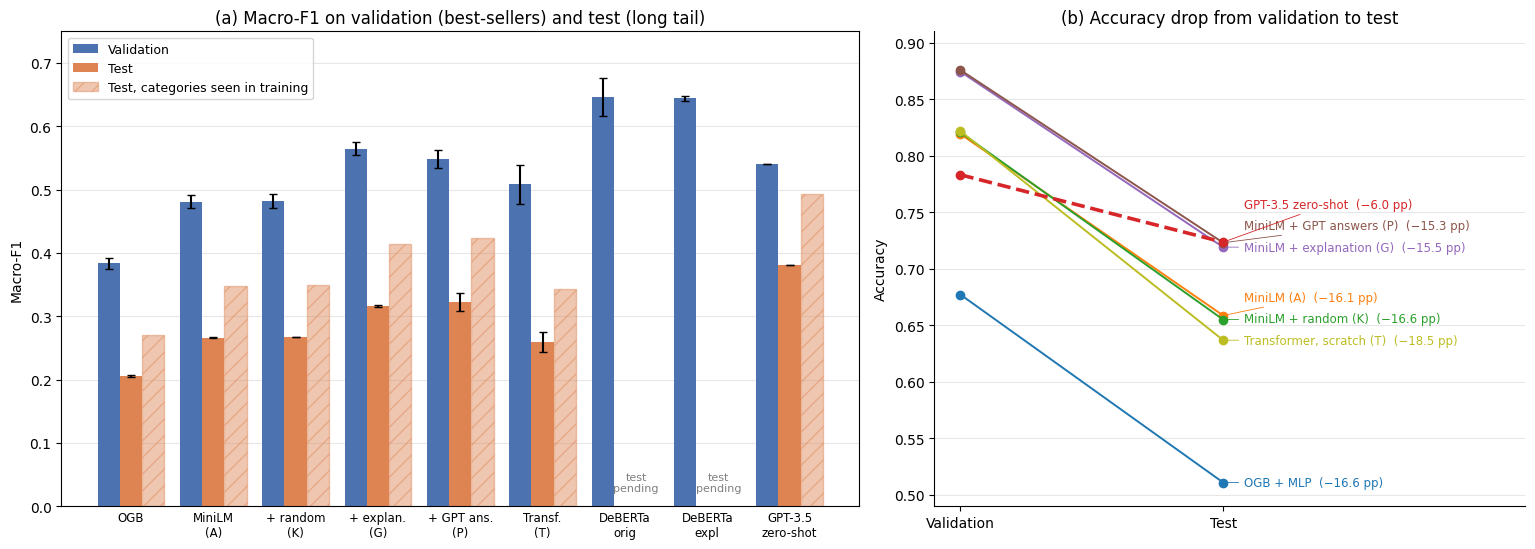

In [22]:
import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt

# --- In the notebook, replace this block with:  val, test = val_table, test_table ---
val, test = val_table, test_table
# ---------------------------------------------------------------------------------

SHORT = {"OGB features + MLP": "OGB", "MiniLM text + MLP (A)": "MiniLM\n(A)",
         "MiniLM text + random dims + MLP (K)": "+ random\n(K)",
         "MiniLM text+explanation + MLP (G)": "+ explan.\n(G)",
         "MiniLM text + GPT answers + MLP (P_MLP)": "+ GPT ans.\n(P)",
         "Text Transformer from scratch (T)": "Transf.\n(T)",
         "DeBERTa-orig + MLP": "DeBERTa\norig", "DeBERTa-expl + MLP": "DeBERTa\nexpl",
         "GPT-3.5 first answer (no training)": "GPT-3.5\nzero-shot"}
LONG = {"OGB features + MLP": "OGB + MLP", "MiniLM text + MLP (A)": "MiniLM (A)",
        "MiniLM text + random dims + MLP (K)": "MiniLM + random (K)",
        "MiniLM text+explanation + MLP (G)": "MiniLM + explanation (G)",
        "MiniLM text + GPT answers + MLP (P_MLP)": "MiniLM + GPT answers (P)",
        "Text Transformer from scratch (T)": "Transformer, scratch (T)",
        "GPT-3.5 first answer (no training)": "GPT-3.5 zero-shot"}
df = val.merge(test, on="model", how="left", suffixes=("_val", "_test"))
df = df[df.model.isin(SHORT)].reset_index(drop=True)
x = np.arange(len(df))
labels = [SHORT[m] for m in df.model]
has_test = df.test_acc.notna().values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})

# (a) Macro-F1: validation, test, test on seen categories
w = 0.27
ax1.bar(x - w, df.val_macro_f1, w, yerr=df.f1_std_val.fillna(0), capsize=3, color="#4C72B0", label="Validation")
ax1.bar(x, df.test_macro_f1, w, yerr=df.f1_std_test.fillna(0), capsize=3, color="#DD8452", label="Test")
ax1.bar(x + w, df["test_seen macro-F1"], w, color="#DD8452", alpha=0.45, hatch="//", edgecolor="#DD8452",
        label="Test, categories seen in training")
for i in np.flatnonzero(~has_test):
    ax1.text(x[i] + w / 2, 0.02, "test\npending", ha="center", va="bottom", fontsize=8, color="grey")
ax1.set_xticks(x, labels, fontsize=8.5)
ax1.tick_params(axis="x", length=0)
ax1.set(ylabel="Macro-F1", ylim=(0, 0.75), title="(a) Macro-F1 on validation (best-sellers) and test (long tail)")
ax1.grid(axis="y", alpha=0.3); ax1.set_axisbelow(True)
ax1.legend(fontsize=9, loc="upper left")

# (b) Accuracy: validation -> test, labels spread so they do not overlap
idx = [i for i in range(len(df)) if has_test[i]]
colours = dict(zip(idx, plt.cm.tab10(np.linspace(0, 1, 10))[[0, 1, 2, 4, 5, 8, 9]]))
for i in idx:
    if df.model[i].startswith("GPT"):
        colours[i] = np.array([0.84, 0.15, 0.16, 1.0])
for i in idx:
    is_gpt = df.model[i].startswith("GPT")
    ax2.plot([0, 1], [df.val_acc[i], df.test_acc[i]], color=colours[i], lw=2.6 if is_gpt else 1.4,
             ls="--" if is_gpt else "-", marker="o")
# place labels at least `gap` apart, in test-accuracy order
gap, ys = 0.019, {}
for i in sorted(idx, key=lambda k: df.test_acc[k]):
    y_lab = df.test_acc[i]
    if ys:
        y_lab = max(y_lab, max(ys.values()) + gap)
    ys[i] = y_lab
for i in idx:
    ax2.annotate(f"{LONG[df.model[i]]}  (−{100 * (df.val_acc[i] - df.test_acc[i]):.1f} pp)",
                 xy=(1, df.test_acc[i]), xytext=(1.08, ys[i]), textcoords="data", va="center", fontsize=8.5,
                 color=colours[i], arrowprops=dict(arrowstyle="-", color=colours[i], lw=0.6))
ax2.set_xticks([0, 1], ["Validation", "Test"])
ax2.set_xlim(-0.1, 2.15)
ax2.set_ylim(0.49, 0.91)
ax2.set(ylabel="Accuracy", title="(b) Accuracy drop from validation to test")
ax2.grid(axis="y", alpha=0.3)
ax2.spines[["right", "top"]].set_visible(False)

fig.tight_layout()
fig.savefig("text_only_val_vs_test.png", dpi=250, bbox_inches="tight")

plt.show()

## 7. Appendix A: does truncation hurt accuracy?

`scripts/analyze_truncation.py` splits validation and test products into truncated (more than 256 MiniLM tokens) and non-truncated groups, compares accuracy, reweights the non-truncated group to the truncated group's category mix, and runs the same comparison for GPT's first answer, which is not affected by MiniLM's limit. Here it uses the text-only arms only; it reads the saved weights, so run Section 5.3 first. Arms that `src/arms.py` does not know are skipped with a message.

In [21]:
run("analyze_truncation", "--arms", "A", "G", "P_MLP")

$ <home>\miniconda3\envs\cs5284\python.exe scripts/analyze_truncation.py --arms A G P_MLP
truncated: 16.3% of all products; median length 106 tokens
<home>\miniconda3\envs\cs5284\Lib\site-packages\torch\_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()

Mean over seeds (gap = long minus short; negative = truncated products are classified worse)
             n_long  n_short  acc_long  acc_short  gap_raw  gap_raw_ci95  gap_class_matched  gap_minus_gpt_gap
split arm                                                                                                     
val   GPT       294     1278    0.8469     0.7684   0.0786        0.0472             0.0580             0.0000
      A         294     

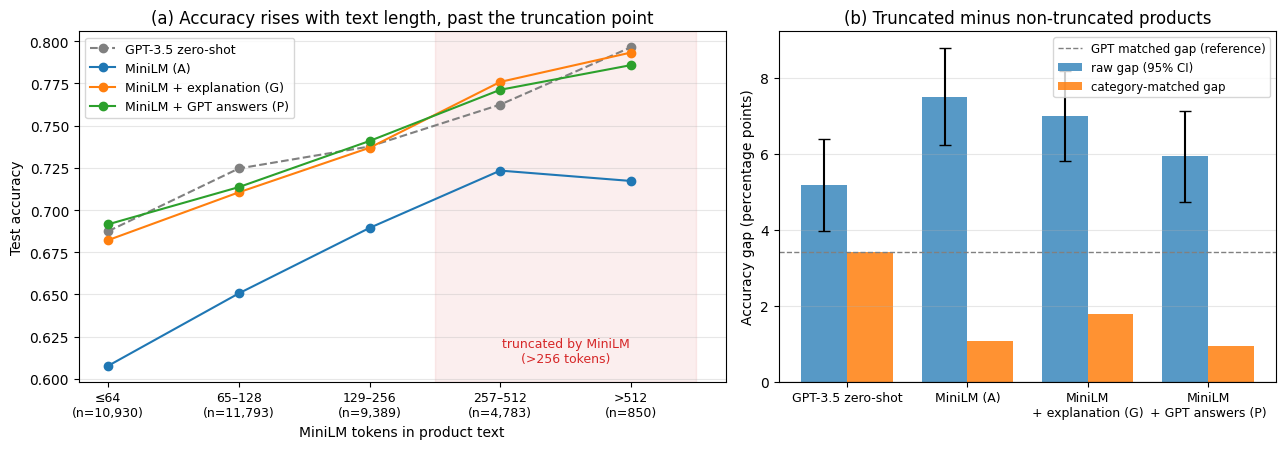

In [22]:
import matplotlib.pyplot as plt

summ = pd.read_csv(REPO / "results" / "2_text_only" / "truncation_summary.csv")
bins = pd.read_csv(REPO / "results" / "2_text_only" / "truncation_bins.csv")
split = "test"
labels = {"GPT": "GPT-3.5 zero-shot", "A": "MiniLM (A)", "G": "MiniLM + explanation (G)", "P_MLP": "MiniLM + GPT answers (P)"}
order = ["<=64", "65-128", "129-256", "257-512 (truncated)", ">512 (truncated)"]
xt = ["≤64", "65–128", "129–256", "257–512", ">512"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

# (a) accuracy by length bin
acc = bins[bins.split == split].groupby(["arm", "length_bin"])["acc"].mean().unstack()[order]
n = bins[(bins.split == split) & (bins.arm == "GPT")].set_index("length_bin")["n"][order]
for arm, style in [("GPT", dict(ls="--", color="grey")), ("A", {}), ("G", {}), ("P_MLP", {})]:
    if arm in acc.index:
        ax1.plot(range(5), acc.loc[arm], marker="o", label=labels[arm], **style)
ax1.axvspan(2.5, 4.5, color="tab:red", alpha=0.08)
ax1.text(3.5, ax1.get_ylim()[0] + 0.01, "truncated by MiniLM\n(>256 tokens)", ha="center", va="bottom", fontsize=9, color="tab:red")
ax1.set_xticks(range(5), [f"{t}\n(n={n[o]:,})" for t, o in zip(xt, order)], fontsize=9)
ax1.set(xlabel="MiniLM tokens in product text", ylabel=f"{split.capitalize()} accuracy",
        title="(a) Accuracy rises with text length, past the truncation point")
ax1.grid(axis="y", alpha=0.3); ax1.legend(fontsize=9, loc="upper left")

# (b) gap truncated minus non-truncated: raw (with 95% CI) and category-matched
g = summ[summ.split == split].groupby("arm")[["gap_raw", "gap_raw_ci95", "gap_class_matched"]].mean()
arms = [a for a in ["GPT", "A", "G", "P_MLP"] if a in g.index]
xs = np.arange(len(arms)); w = 0.38
ax2.bar(xs - w / 2, 100 * g.loc[arms, "gap_raw"], w, yerr=100 * g.loc[arms, "gap_raw_ci95"], capsize=4,
        label="raw gap (95% CI)", color="tab:blue", alpha=0.75)
ax2.bar(xs + w / 2, 100 * g.loc[arms, "gap_class_matched"], w, label="category-matched gap", color="tab:orange", alpha=0.85)
ax2.axhline(0, color="black", lw=0.8)
ax2.axhline(100 * g.loc["GPT", "gap_class_matched"], color="grey", ls="--", lw=1, label="GPT matched gap (reference)")
ax2.set_xticks(xs, [labels[a].replace(" + ", "\n+ ") for a in arms], fontsize=9)
ax2.set(ylabel="Accuracy gap (percentage points)", title="(b) Truncated minus non-truncated products")
ax2.grid(axis="y", alpha=0.3); ax2.legend(fontsize=8.5, loc="upper right")

fig.tight_layout()
out = REPO / "results" / "2_text_only" / "figures"; out.mkdir(parents=True, exist_ok=True)
fig.savefig(out / "truncation_test.png", dpi=250, bbox_inches="tight")
plt.show()